In [74]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report,confusion_matrix, roc_auc_score

In [11]:
df = pd.read_csv(r"D:\1_Python Programmes\Projects\HDD\data\heart_disease_cleaned.csv")

df.describe(include = "all")

,id,age,sex,dataset,cp,trestbps,chol,fbs,restecg,thalch,exang,oldpeak,slope,ca,thal,num
count,920.000000,920.000000,920,920,920,860.000000,718.000000,830,918,865.000000,865,858.000000,611,309.000000,434,920.000000
unique,NaN,NaN,2,4,4,NaN,NaN,2,3,NaN,2,NaN,3,NaN,3,NaN
top,NaN,NaN,Male,Cleveland,asymptomatic,NaN,NaN,False,normal,NaN,False,NaN,flat,NaN,normal,NaN
freq,NaN,NaN,726,304,496,NaN,NaN,692,551,NaN,528,NaN,345,NaN,196,NaN
mean,460.500000,53.510870,NaN,NaN,NaN,132.286047,246.832869,NaN,NaN,137.545665,NaN,0.878788,NaN,0.676375,NaN,0.553261
std,265.725422,9.424685,NaN,NaN,NaN,18.536175,58.527062,NaN,NaN,25.926276,NaN,1.091226,NaN,0.935653,NaN,0.497426
min,1.000000,28.000000,NaN,NaN,NaN,80.000000,85.000000,NaN,NaN,60.000000,NaN,-2.600000,NaN,0.000000,NaN,0.000000
25%,230.750000,47.000000,NaN,NaN,NaN,120.000000,210.000000,NaN,NaN,120.000000,NaN,0.000000,NaN,0.000000,NaN,0.000000
50%,460.500000,54.000000,NaN,NaN,NaN,130.000000,239.500000,NaN,NaN,140.000000,NaN,0.500000,NaN,0.000000,NaN,1.000000
75%,690.250000,60.000000,NaN,NaN,NaN,140.000000,276.750000,NaN,NaN,157.000000,NaN,1.500000,NaN,1.000000,NaN,1.000000


In [69]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

numerical_features = [
    "age", "trestbps", "chol",
    "thalch", "oldpeak", "ca"
]

categorical_features = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "thal"
]

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    ))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant",
        fill_value="Unknown"
    )),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

preprocessor_tree = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

In [77]:
X = df.drop(columns = ["id","dataset","num"])
y = df["num"]

for col in categorical_features:
    X[col] = X[col].map(
        lambda value: str(value) if pd.notna(value) else np.nan
    )

# Same train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

tree_pipeline = Pipeline([
    ("preprocessor" , preprocessor_tree),
    ("classifier", DecisionTreeClassifier(random_state=42))
])
# print("Training shape:", X_train.shape)
# print("Testing shape:", X_test.shape)

In [79]:
tree_pipeline.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [83]:
y_pred_tree = tree_pipeline.predict(X_test)

y_prob_tree = tree_pipeline.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred_tree))
print("Precision:", precision_score(y_test, y_pred_tree))
print("Recall:", recall_score(y_test, y_pred_tree))
print("F1 Score:", f1_score(y_test, y_pred_tree))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_tree))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_tree))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_tree))

Accuracy: 0.7554347826086957
Precision: 0.7567567567567568
Recall: 0.8235294117647058
F1 Score: 0.7887323943661971
ROC-AUC: 0.7471305595408895

Confusion Matrix:
[[55 27]
 [18 84]]

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.67      0.71        82
           1       0.76      0.82      0.79       102

    accuracy                           0.76       184
   macro avg       0.76      0.75      0.75       184
weighted avg       0.76      0.76      0.75       184



In [84]:
y_train_pred = tree_pipeline.predict(X_train)
y_train_prob = tree_pipeline.predict_proba(X_train)[:, 1]

# Test predictions
y_test_pred = tree_pipeline.predict(X_test)
y_test_prob = tree_pipeline.predict_proba(X_test)[:, 1]

print("Training Accuracy:",
      accuracy_score(y_train, y_train_pred))

print("Testing Accuracy:",
      accuracy_score(y_test, y_test_pred))

print("\nTraining ROC-AUC:",
      roc_auc_score(y_train, y_train_prob))

print("Testing ROC-AUC:",
      roc_auc_score(y_test, y_test_prob))

Training Accuracy: 1.0
Testing Accuracy: 0.7554347826086957

Training ROC-AUC: 1.0
Testing ROC-AUC: 0.7471305595408895


In [86]:
tree = tree_pipeline.named_steps["classifier"]

print("Tree depth:", tree.get_depth())
print("Number of leaves:", tree.get_n_leaves())

Tree depth: 16
Number of leaves: 140


In [89]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Define 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Perform cross-validation
dt_cv_scores = cross_val_score(
    tree_pipeline,
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

# Display results
print("ROC-AUC for each fold:", dt_cv_scores)
print("Mean ROC-AUC:", dt_cv_scores.mean())
print("Standard Deviation:", dt_cv_scores.std())

ROC-AUC for each fold: [0.6947524  0.6260788  0.74438833 0.71127946 0.75392817]
Mean ROC-AUC: 0.706085432182993
Standard Deviation: 0.04541479108957539


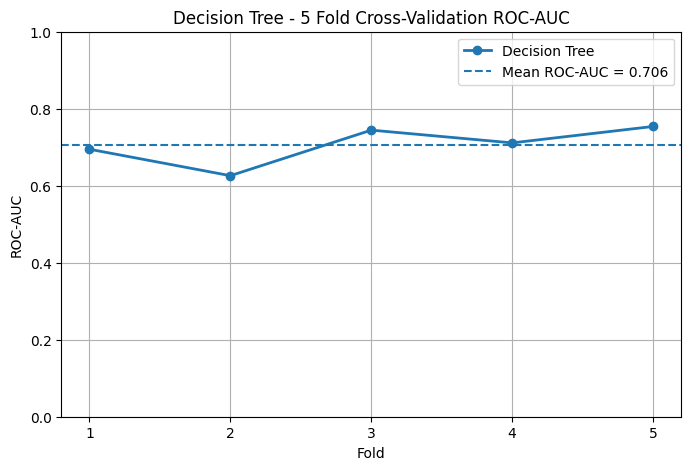

In [95]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 6),
    dt_cv_scores,
    marker='o',
    linewidth=2,
    label='Decision Tree'
)

plt.axhline(
    y=dt_cv_scores.mean(),
    linestyle='--',
    label=f'Mean ROC-AUC = {dt_cv_scores.mean():.3f}'
)

plt.title('Decision Tree - 5 Fold Cross-Validation ROC-AUC')
plt.xlabel('Fold')
plt.ylabel('ROC-AUC')
plt.xticks(range(1, 6))
plt.ylim(0, 1)
plt.grid(True)
plt.legend()
plt.show()


In [101]:
import joblib

# joblib.dump(tree_pipeline , "models/decision_tree_model.pkl")

In [105]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

lr_model = joblib.load("models/logistic_r_model.pkl")
knn_model = joblib.load("models/heart_disease_knn.pkl")
decision_tree_model = joblib.load("models/decision_tree_model.pkl")

models = {
    "Logistic Regression": lr_model,
    "KNN (K=16)": knn_model,
    "Decision Tree": decision_tree_model
}

comparison = {}

for name, model in models.items():

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

    comparison[name] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "Specificity": tn / (tn + fp),
        "F1 Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }

comparison_df = pd.DataFrame(comparison).T

comparison_df = comparison_df.round(4)

display(comparison_df)


comparison_df.to_csv(
    "reports/model_comparison.csv",
    index=True,
    index_label="Model"
)

print("Model comparison report saved successfully!")

,Accuracy,Precision,Recall,Specificity,F1 Score,ROC-AUC
Logistic Regression,0.8533,0.8505,0.8922,0.8049,0.8708,0.9143
KNN (K=16),0.8478,0.8700,0.8529,0.8415,0.8614,0.9030
Decision Tree,0.7554,0.7568,0.8235,0.6707,0.7887,0.7471


Model comparison report saved successfully!
